# Inspect actual compiled surfaces

Compare a geometry-only preview with compiled constructions and diagnostic evidence.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`widget_epjson(path)` reads a compiled World-coordinate model and its adjacent reports for inline inspection. `write_viewer` writes a standalone asset bundle, while `view_epjson` returns a server handle. These interfaces inspect an existing artifact; they do not run EnergyPlus.

The viewer screenshot identifies the controls shared by both inspection routes. The important extra evidence in a compiled model is the assigned thermal construction and engine object metadata. Select a wall and compare the displayed layers and U-values with the original envelope assumptions rather than judging only the shell's appearance.

Reference: [Existing viewer controls and target/context separation](../../docs/figures/viewer-controls.png). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Compile an explicit building

Compiled epJSON contains thermal constructions and load assignments unavailable to a geometry-only preview. Neither display mode runs EnergyPlus by itself.

### Read the code and output

`compiler.write` prepares the three related artifacts together. The widget reads from this directory so the scene and report correspond. A missing acceptance flag is not a successful simulation flag: compilation and geometry inspection can happen before an annual run exists.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

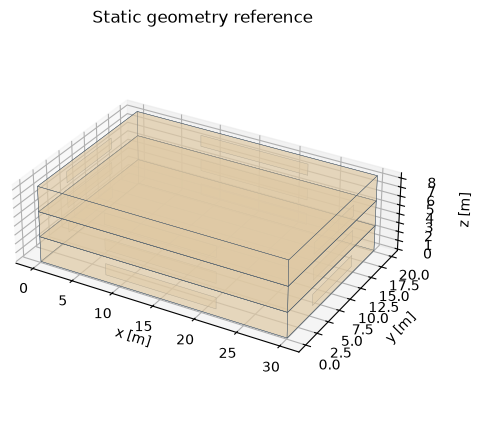

In [2]:
from epsm_core.viewer import widget_epjson,write_viewer,view_epjson
b=building(); compiler=EnergyPlusCompiler(engine())
report=compiler.write(b,OUT/"compiled")
widget=widget_epjson(OUT/"compiled/model.epJSON")
display(widget)
preview(b,"Static geometry reference",interactive=False)

## Inspect construction evidence

Select a wall in the widget to inspect source epJSON, nominal/applied U-values and layer metadata. This table previews the same report evidence.

### Read the code and output

The table groups constructions by their compiled roles. Nominal and applied U-values can differ when a declared conductance adjustment is applied. Layer metadata explains what material model produced the surface; it is not a measured wall survey inferred from the geometry.

,index,applied,applied_u_w_m2k,nominal,nominal_u_w_m2k
0,basement_ceiling,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
1,basement_wall,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
2,ground,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
3,intermediate_floor,{'layers': [{'material': {'conductivity_w_mk':...,3.476483,{'layers': [{'material': {'conductivity_w_mk':...,3.476483
4,top,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
5,unconditioned_basement_wall,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
6,unconditioned_ground,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
7,unconditioned_top,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
8,unconditioned_wall,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669
9,wall,{'layers': [{'material': {'conductivity_w_mk':...,0.247669,{'layers': [{'material': {'conductivity_w_mk':...,0.247669


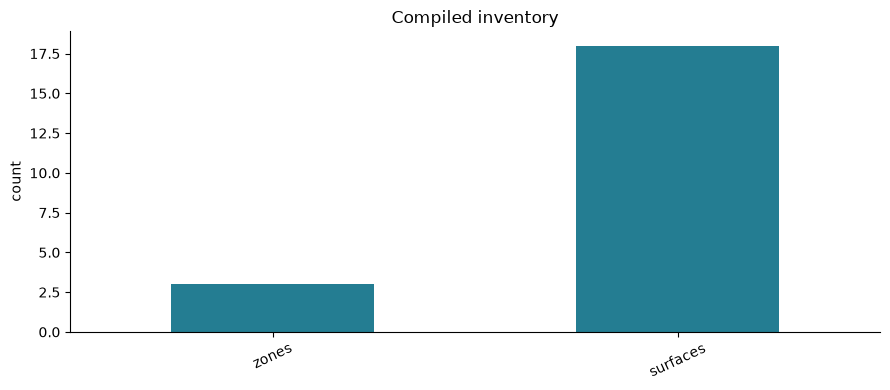

In [3]:
table(pd.DataFrame.from_dict(report.data["constructions"],orient="index").reset_index())
assert not widget.scene["report"].get("geometry_only",False)
bars({"zones":len(report.data["zones"]),"surfaces":len(report.data["surfaces"])},"count","Compiled inventory")

## Preserve the standalone viewer API

The browser-server handle remains available for standalone work. It must remain open while a browser uses its URL; the context manager below is only a short HTTP smoke test.

### Read the code and output

The short context manager checks that a local standalone server responds, then closes it. Its printed success is an HTTP check, not a live-browser rendering check. For prolonged inspection, keep the handle alive. The notebook widget follows a separate lifetime through its own `close()` method.

In [4]:
from urllib.request import urlopen
bundle=write_viewer(OUT/"compiled/model.epJSON",OUT/"browser-bundle")
with view_epjson(OUT/"compiled/model.epJSON",directory=OUT/"served",launch_browser=False) as handle:
    assert urlopen(handle.url).status==200
    print("Standalone viewer served successfully")
table([{ "file":p.name,"bytes":p.stat().st_size} for p in bundle.iterdir()])

Standalone viewer served successfully


,file,bytes
0,three.module.js,603113
1,model.json,111312
2,widget-entry.js,4508
3,renderer.js,18130
4,index.html,5414
5,LICENSE,1081
6,vendor.json,465
7,widget.js,529295
8,three.core.js,1403455
9,viewer.js,402


,file,bytes
0,three.module.js,603113
1,model.json,111312
2,widget-entry.js,4508
3,renderer.js,18130
4,index.html,5414
5,LICENSE,1081
6,vendor.json,465
7,widget.js,529295
8,three.core.js,1403455
9,viewer.js,402


## Interpretation and next experiment

Use the compiled viewer for thermal evidence and the geometry widget for early shape review. Keep acceptance diagnostics separate from visual plausibility.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.